In [ ]:
https://github.com/manoelgadi/PSDMA/raw/refs/heads/main/datasets/UN.csv

In [ ]:
import pandas as pd


un_url = 'https://raw.githubusercontent.com/manoelgadi/PSDMA/refs/heads/main/datasets/UN.csv'
df_un = pd.read_csv(un_url)


print(f"Dataset Shape: {df_un.shape}")
print(f"Number of Countries/Territories: {df_un.shape[0]}")
print(f"Number of Columns: {df_un.shape[1]}\n")

display(df_un.head())

Dataset Shape: (207, 14)
Number of Countries/Territories: 207
Number of Columns: 14



,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.00
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.00
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.36
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_un.describe()

,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
count,197.000000,144.000000,76.000000,76.000000,196.00000,196.000000,201.000000,197.000000,165.000000,165.000000,160.000000,160.000000
mean,3.528782,43.430556,11.410526,11.275000,63.62551,68.391837,43.477612,6261.954315,76.460606,46.794545,17.554662,27.906200
std,1.761974,23.706732,3.049834,3.475135,9.78687,11.041234,38.756041,9355.659390,7.687047,16.810472,17.813000,26.580664
min,1.190000,2.000000,3.300000,2.000000,36.00000,39.100000,2.000000,36.000000,51.200000,1.900000,0.200000,0.200000
25%,1.950000,21.000000,9.750000,9.325000,57.37500,59.600000,12.000000,442.000000,72.300000,37.000000,2.952000,4.847000
50%,3.070000,47.000000,11.250000,11.650000,66.50000,72.150000,30.000000,1779.000000,76.800000,48.400000,10.829000,20.100000
75%,4.980000,64.000000,13.900000,13.650000,70.90000,76.425000,66.000000,7272.000000,81.200000,56.400000,27.575000,48.025000
max,8.000000,86.000000,17.200000,17.800000,77.40000,82.900000,169.000000,42416.000000,93.000000,90.600000,79.100000,93.400000


In [ ]:
import pandas as pd
from sklearn.impute import SimpleImputer

missing_percent = df_un.isnull().median() * 100
print("Percentage of missing observations:")
print(missing_percent)

df_filtered = df_un.drop(columns=['educationMale', 'educationFemale'])

identifiers = ['country', 'region']
numeric_cols = df_filtered.select_dtypes(include=['number']).columns

imputer = SimpleImputer(strategy='median')
imputed_numeric = imputer.fit_transform(df_filtered[numeric_cols])
df_imputed_numeric = pd.DataFrame(imputed_numeric, columns=numeric_cols)

df_final = pd.concat([df_filtered[identifiers], df_imputed_numeric], axis=1)

print("\nMissing values remaining in final DataFrame:")
print(df_final.isnull().sum())

display(df_final.head())

Percentage of missing observations:
country                     0.0
region                      0.0
tfr                         0.0
contraception               0.0
educationMale             100.0
educationFemale           100.0
lifeMale                    0.0
lifeFemale                  0.0
infantMortality             0.0
GDPperCapita                0.0
economicActivityMale        0.0
economicActivityFemale      0.0
illiteracyMale              0.0
illiteracyFemale            0.0
dtype: float64

Missing values remaining in final DataFrame:
country                   0
region                    0
tfr                       0
contraception             0
lifeMale                  0
lifeFemale                0
infantMortality           0
GDPperCapita              0
economicActivityMale      0
economicActivityFemale    0
illiteracyMale            0
illiteracyFemale          0
dtype: int64


,country,region,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,47.0,45.0,46.00,154.0,2848.0,87.5,7.2,52.800,85.00
1,Albania,Europe,2.60,47.0,68.0,74.00,32.0,863.0,76.8,48.4,10.829,20.10
2,Algeria,Africa,3.81,52.0,67.5,70.30,44.0,1531.0,76.4,7.8,26.100,51.00
3,American.Samoa,Asia,3.07,47.0,68.0,73.00,11.0,1779.0,58.8,42.4,0.264,0.36
4,Andorra,Europe,3.07,47.0,66.5,72.15,30.0,1779.0,76.8,48.4,10.829,20.10


In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_cols = df_final.select_dtypes(include=['number']).columns

scaler = StandardScaler()
scaled_numeric = scaler.fit_transform(df_final[numeric_cols])

df_scaled_un = pd.DataFrame(scaled_numeric, columns=numeric_cols)

df_scaled_final = pd.concat([df_final[['country', 'region']], df_scaled_un], axis=1)

check_df = pd.DataFrame({
    'Mean': df_scaled_un.mean(),
    'Std Dev': df_scaled_un.std(ddof=0)
})

print("Verification of means (~0) and standard deviations (~1):")
display(check_df)

display(df_scaled_final.head())

Verification of means (~0) and standard deviations (~1):


,Mean,Std Dev
tfr,-8.366898e-17,1.0
contraception,-4.719789e-17,1.0
lifeMale,1.737740e-16,1.0
lifeFemale,-3.690017e-16,1.0
infantMortality,-2.145359e-17,1.0
GDPperCapita,5.148860e-17,1.0
economicActivityMale,1.553240e-15,1.0
economicActivityFemale,8.849604e-16,1.0
illiteracyMale,5.148860e-17,1.0
illiteracyFemale,6.007004e-17,1.0


,country,region,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,1.975954,0.125584,-1.972337,-2.101632,2.906362,-0.349277,1.603042,-2.665466,2.317990,2.502358
1,Albania,Europe,-0.527921,0.125584,0.443422,0.503134,-0.290522,-0.566115,0.039531,0.085446,-0.327698,-0.256491
2,Algeria,Africa,0.176658,0.378463,0.390905,0.158933,0.023925,-0.493144,-0.018918,-2.625404,0.634926,1.057044
3,American.Samoa,Asia,-0.254241,0.125584,0.443422,0.410107,-0.840806,-0.466053,-2.590676,-0.315172,-0.993675,-1.095624
4,Andorra,Europe,-0.254241,0.125584,0.285872,0.331034,-0.342930,-0.466053,0.039531,0.085446,-0.327698,-0.256491


Question: Why is scaling required before clustering?

Scaling is required before clustering in large datasets, to create comparability. Scaling prevents variables with large absolute magnitudes from absoultuely dominating variables with smaller ranges. Typical methods of scaling include the standardscaler, which prouces a zero mean and a unit variance of 1, on fitted data. Another technique would be the minmax scalar, which rescales data to a bounded range. Either of these techniques are reccomended before clustering any distance based algorithms.

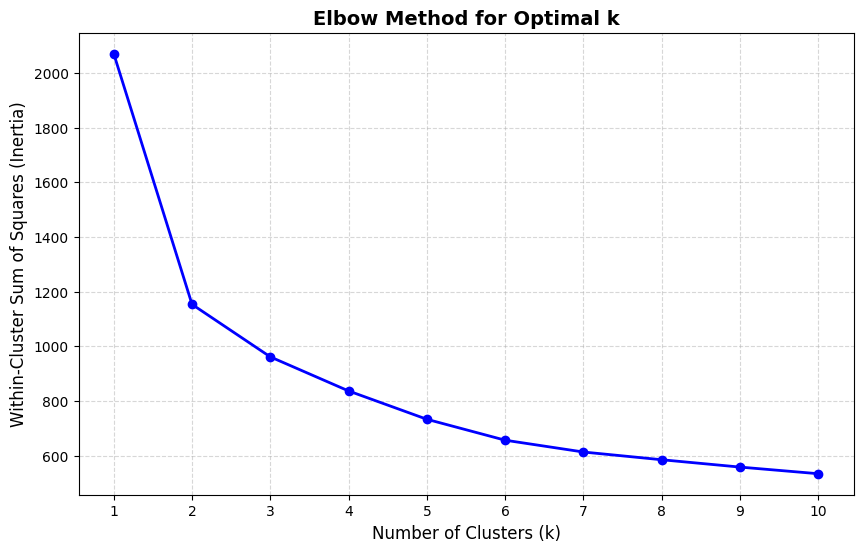

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = range(1, 11)
inertia_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled_un)
    inertia_scores.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia_scores, marker='o', linestyle='-', color='b', linewidth=2)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Within-Cluster Sum of Squares (Inertia)', fontsize=12)
plt.title('Elbow Method for Optimal k', fontsize=14, fontweight='bold')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
inertia_scores

[2070.0000000000005,
 1153.2698756705329,
 961.2553107103748,
 836.654528483528,
 733.0397856256154,
 656.4973623133866,
 613.308832645383,
 585.0578238033195,
 558.2283129217475,
 533.9335903801584]

In [ ]:
sum(inertia_scores)

8701.245422554046

In [ ]:
[x/sum(inertia_scores) for x in inertia_scores]

[0.23789697905020138,
 0.13254078234377828,
 0.1104733016975656,
 0.09615342262555648,
 0.0842453867265416,
 0.07544866630375853,
 0.07048517802470633,
 0.06723840041183317,
 0.06415498998278946,
 0.06136289283326924]

In [ ]:
0.23789697905020138 + 0.13254078234377828

0.37043776139397966

In [ ]:
from sklearn.cluster import KMeans

kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
df_final['cluster_k2'] = kmeans_2.fit_predict(df_scaled_un)

kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_final['cluster_k3'] = kmeans_3.fit_predict(df_scaled_un)

display(df_final[['country', 'region', 'cluster_k2', 'cluster_k3']].sample(15, random_state=42))

,country,region,cluster_k2,cluster_k3
161,Sao.Tome,Africa,0,1
15,Barbados,America,0,0
73,Guam,Oceania,0,1
96,Kiribati,Oceania,0,1
166,Singapore,Asia,0,0
9,Australia,Oceania,0,0
100,Kyrgyzstan,Asia,0,1
135,New.Zealand,Oceania,0,0
18,Belize,America,0,1
148,Philippines,Asia,0,1


In [ ]:
df_final.to_excel("Developing_Countries.xlsx")

**Can the world be meaningfully divided into only two clusters (developed vs developing)?**

No, the world can not be meaningfully divided into only two clusters.

**How many clusters are actually suggested by the data according to the Elbow Rule?**

The Elbow Rule shows us that four clusters work for this scenario.

**How much of the data structure is explained by two clusters compared to the optimal number of clusters?**

50% of the data structure is explained by the first four clusters, as opposed to only 37% explained by just two clusters.

**Does the evidence support the claim in Factfulness that the world cannot be divided into only two groups but into 4?**

Yes, the evidence found here does support this claim, as more of the data structure is explained by four groups, rather than just the two.

7. Conclusion
**Explain whether the analysis supports the idea that the world cannot be divided into only two groups.**

The statistical analysis reveals that the world cannot be divided in soley two groups, as utilizing only the first two clusters only explains 37% of the variance in the data.

**For your final clustering solution, choose one country from each cluster to represent and explain that cluster.**

We pick Luxembourg from the developed cluster.
We pick Cuba from the developing cluster.

For each selected country, discuss:

Why does this country appear to belong to this cluster? **bold text**

Luxembourg is grouped with other countries of relatively higher economic means and infastructure, such as France and Germany. Meanwhile, Cuba belongs in the group of relatively lower economic means and infastructure, like Angola and Botswana.

**Does it look similar to the other countries assigned to the same cluster?**

Yes, the countries share many characteristics with other countries from the same respective group.

**What characteristics distinguish this cluster from the others?**

The cluster that Luxembourg belongs to has lower infant mortality, longer life spans, higher GDP per capita. Likewise, Cuba's group has higher infant mortality, shorter life spans, and lower GDP per capita.

**Is there anything surprising about the countries grouped together?**

Given the chosen indicators of development, the grouping of countries is sensical given that the more developed countries have better economic performance and improved life conditions